# Stock movement forecasting using LOB

Before start, we need to test some libraries in order to build a reasonable dataset for the neural network architecture.

In [1]:
import time 
import pandas
import random
import json, argparse

# ML
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from plotly import graph_objects as go
from sklearn import preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, roc_auc_score

# pytorch
import torch.nn as nn
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import torch.utils

# software modules
import models_regression as Models
import utils
import dataset as Dataset

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print('Using device:', device)

Using device: cuda:0


## Load Data

In [2]:
df = pd.read_parquet('./Data/FI-2010-Cleaned/NoAuction/Zscore/WRT1V.parquet')
df = df.astype(float)
df.drop(columns=['Day'], inplace=True)

target_cols = ['Label_10', 'Label_20', 'Label_30', 'Label_50', 'Label_100']
df[target_cols] = df[target_cols].astype(int)

df = df.head(20000)
display(df)

,P_Ask_0,V_Ask_0,P_Bid_0,V_Bid_0,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,Label_10,Label_20,Label_30,Label_50,Label_100
0,1.242406,-0.611621,1.240199,-0.446819,1.241779,-0.663252,1.240732,-0.512393,1.241182,-0.770717,...,-0.499588,1.236425,-0.444236,1.243820,-0.278126,1,1,1,1,1
1,1.241385,-0.678429,1.240199,-0.555044,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1,1,1,1,1
2,1.241385,-0.678429,1.240199,-0.465970,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1,1,1,1,1
3,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,2,2,1,1,1
4,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,1.296517,-0.324348,1.298496,-0.430341,1.295878,-0.720826,1.299042,-0.655960,1.297308,-0.354275,...,-0.407660,1.291370,-0.395518,1.301238,-0.451811,1,1,0,0,0
19996,1.296517,-0.324348,1.298496,-0.430341,1.295878,-0.720826,1.299042,-0.655960,1.297308,-0.354275,...,-0.503573,1.291370,-0.395518,1.300213,-0.215854,1,1,1,0,2
19997,1.296517,-0.391155,1.298496,-0.461517,1.295878,-0.720826,1.299042,-0.608105,1.297308,-0.354275,...,-0.503573,1.291370,-0.395518,1.300213,-0.215854,1,1,1,0,2
19998,1.296517,-0.683773,1.298496,-0.461517,1.295878,-0.720826,1.299042,-0.608105,1.297308,-0.494177,...,-0.503573,1.290353,-0.444236,1.300213,-0.215854,1,1,1,1,2


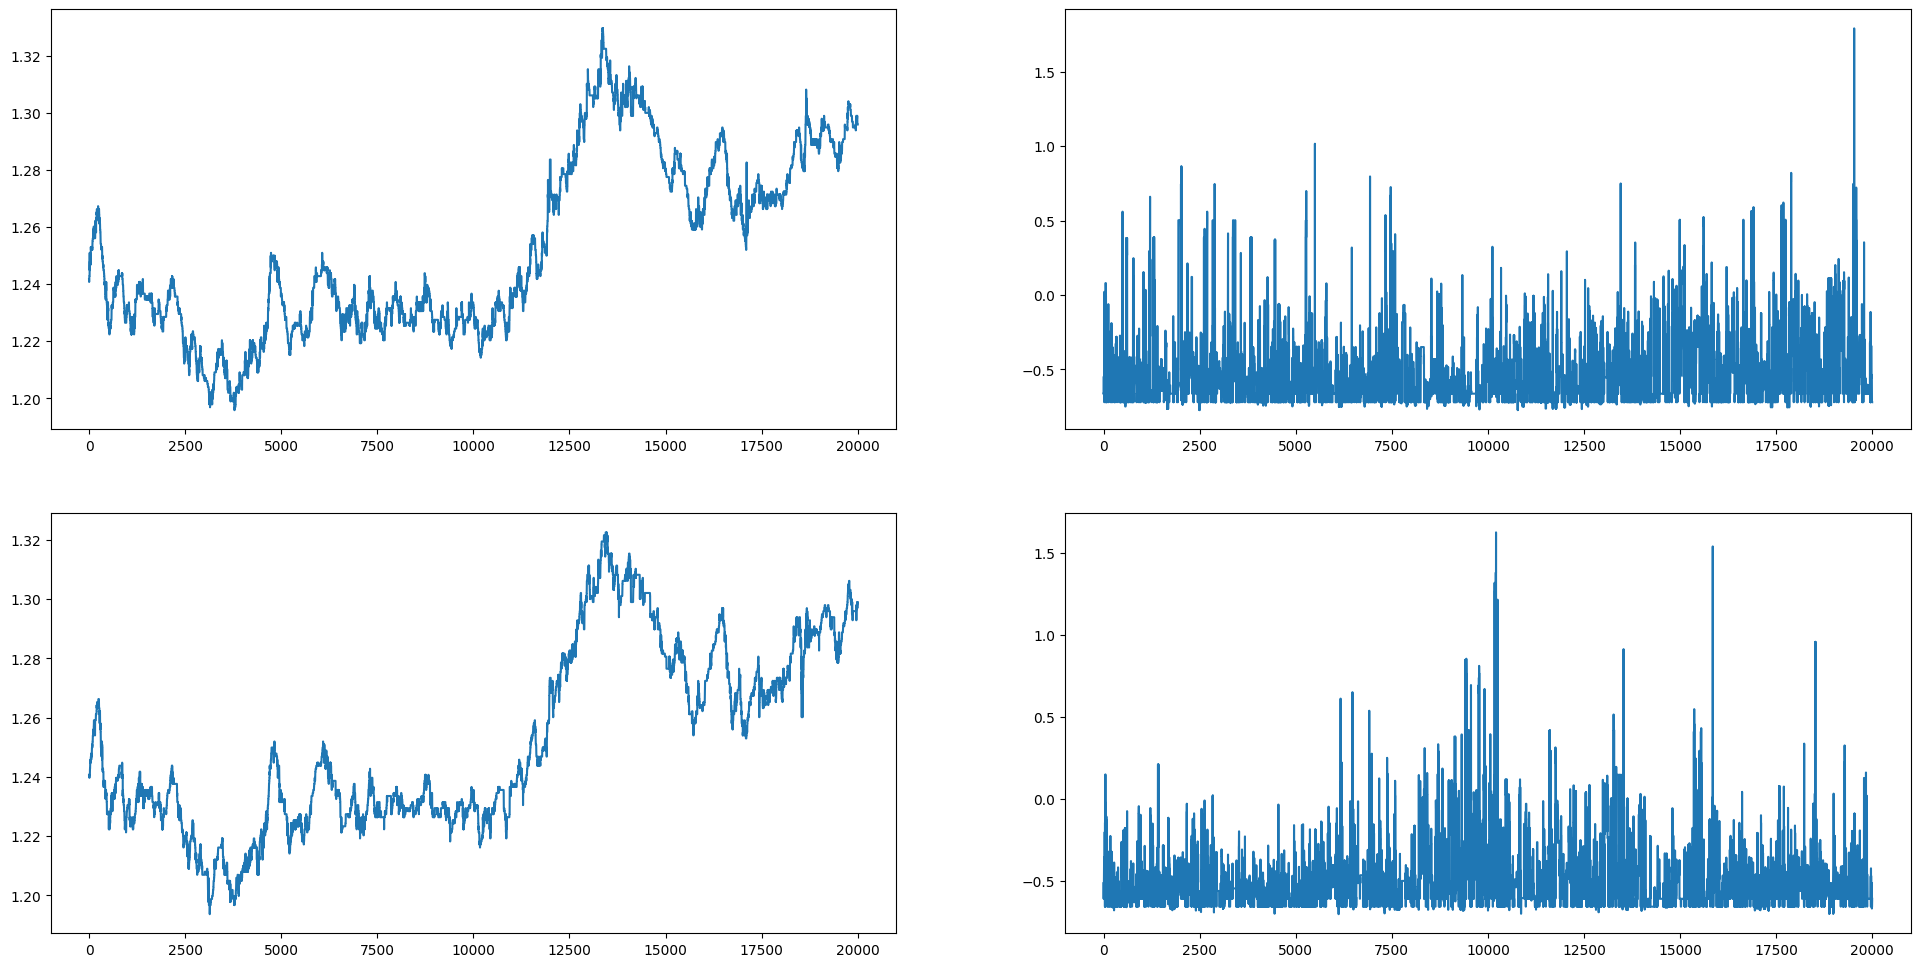

In [4]:
_, axs = plt.subplots(2, 2, figsize=(24,12))
axs[0,0].plot(df['P_Ask_1'])
axs[0,1].plot(df['V_Ask_1'])
axs[1,0].plot(df['P_Bid_1'])
axs[1,1].plot(df['V_Bid_1'])
plt.show()